In [1]:
from pathlib import Path
import pandas as pd
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco-Customer-Churn.txt"
print("File exists: ", DATA_PATH.exists())

File exists:  True


In [2]:
with open(DATA_PATH, 'r', encoding='utf-8') as file:
    for _ in range(5):
        print(file.readline().rstrip())

customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No


In [3]:
df = pd.read_csv(DATA_PATH, sep = ',')
print("shape :", df.shape)
display(df.head())

shape : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
print(df["TotalCharges"].dtype)

str


In [8]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"], errors='coerce')

In [9]:
print(df["TotalCharges"].dtype)
print("Missing total charges", df["TotalCharges"].isnull().sum())

float64
Missing total charges 11


In [10]:
print("Duplicate rows:",df.duplicated().sum())
print("Duplicate customer IDs", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs 0


In [11]:
display(df[df["TotalCharges"].isnull()])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [12]:
df.loc[df["TotalCharges"].isnull(), ['tenure', 'MonthlyCharges', 'TotalCharges' ]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [13]:
df = df.dropna(subset = ["TotalCharges"]).copy()
print("Shape after cleaning", df.shape)
print("Missing values remaining", df.isnull().sum().sum())

Shape after cleaning (7032, 21)
Missing values remaining 0


In [14]:
x = df.drop(columns = ["customerID", "Churn"])

In [15]:
y = df["Churn"]

In [16]:
print("Features shape", x.shape)
print("Target shape", y.shape)

Features shape (7032, 19)
Target shape (7032,)


In [17]:
print(y.value_counts())

Churn
No     5163
Yes    1869
Name: count, dtype: int64


In [18]:
print(y.value_counts(normalize = True).round(3)*100)

Churn
No     73.4
Yes    26.6
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Customer Church Distribution')

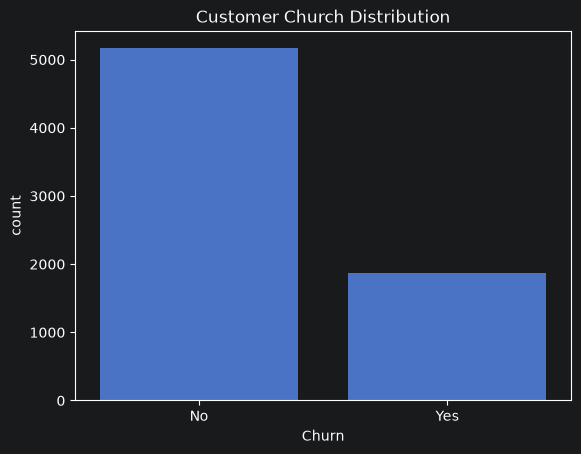

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data = df, x="Churn")
plt.title("Customer Church Distribution")

In [20]:
numeric_features = x.select_dtypes(include = ["float64", "int64"]).columns.tolist()
categorical_features = x.select_dtypes(include = ["category", "object", "bool", "str"]).columns.tolist()
print("Numerical features",numeric_features)
print("Categorical features",categorical_features)

Numerical features ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown = "ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cag", categorical_pipeline, categorical_features)
])
print("numerical features pipline steps", numeric_pipeline.steps)
print("categorical features pipline steps", categorical_pipeline.steps)
print(preprocessor)

numerical features pipline steps [('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]
categorical features pipline steps [('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cag',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
 

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

In [23]:
print("X train shape", X_train.shape)
print("X test shape", X_test.shape)
print("y train shape", y_train.shape)
print("y test shape", y_test.shape)

X train shape (5625, 19)
X test shape (1407, 19)
y train shape (5625,)
y test shape (1407,)


In [24]:
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
print("Processed training shape", X_train_preprocessed.shape)
print("Processed testing shape", X_test_preprocessed.shape)


Processed training shape (5625, 45)
Processed testing shape (1407, 45)


In [25]:
from sklearn.dummy import DummyClassifier
dummy_clf = DummyClassifier(strategy = "most_frequent")
dummy_clf.fit(X_train_preprocessed, y_train)
y_pred_baseline = dummy_clf.predict(X_test_preprocessed)


In [26]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)
print("Baseline accuracy", accuracy_score(y_test, y_pred_baseline))
print("Baseline precision", precision_score(y_test, y_pred_baseline, pos_label = "Yes", zero_division = 0))
print("Baseline recall", recall_score(y_test, y_pred_baseline, pos_label = "Yes",zero_division = 0))
print("Baseline F1-Score", f1_score(y_test, y_pred_baseline, pos_label = "Yes",zero_division = 0))
print("\n confusion matrix")
print(confusion_matrix(y_test, y_pred_baseline, labels = ["No", "Yes"]))


Baseline accuracy 0.7341862117981521
Baseline precision 0.0
Baseline recall 0.0
Baseline F1-Score 0.0

 confusion matrix
[[1033    0]
 [ 374    0]]


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
logistic_model = Pipeline([
    ("processor", preprocessor),
    ("classifier", LogisticRegression(max_iter= 1000, random_state = 24))
])

logistic_model.fit(X_train, y_train)
y_pred_logistic = logistic_model.predict(X_test)

In [28]:
print("Logistic regression accuracy", accuracy_score(y_test, y_pred_logistic))
print("Logistic regression precision", precision_score(y_test, y_pred_logistic, pos_label = "Yes", zero_division = 0))
print("Logistic regression recall", recall_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0))
print("Logistic regression F1-Score", f1_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0))
print("Logistic regression classification report\n", classification_report(y_test, y_pred_logistic, zero_division = 0))
print("\n confusion matrix")
print(confusion_matrix(y_test, y_pred_logistic, labels = ["No" , "Yes"]))

Logistic regression accuracy 0.8038379530916845
Logistic regression precision 0.6484848484848484
Logistic regression recall 0.5721925133689839
Logistic regression F1-Score 0.6079545454545454
Logistic regression classification report
               precision    recall  f1-score   support

          No       0.85      0.89      0.87      1033
         Yes       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


 confusion matrix
[[917 116]
 [160 214]]


In [29]:
churn_probabilities = logistic_model.predict_proba(X_test)[:,1]
print("Minimum:", churn_probabilities.min())
print("Maximum:", churn_probabilities.max())
print("Average:", churn_probabilities.mean())
print("\n first 10 churn probabilities:")
print(churn_probabilities[:10])


Minimum: 0.0014413956223375515
Maximum: 0.8474657995951943
Average: 0.2726629718757723

 first 10 churn probabilities:
[0.01751303 0.59192131 0.00482103 0.20165167 0.1015014  0.4718449
 0.02651812 0.16543101 0.67959955 0.01552463]


In [30]:
print(logistic_model.classes_)

['No' 'Yes']


In [31]:
import pandas as pd
results = pd.DataFrame({
    "Models": ["Baseline", "Logistic regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_baseline),
        accuracy_score(y_test, y_pred_logistic)
    ],
    "Precession": [
        precision_score(y_test, y_pred_baseline, pos_label = "Yes", zero_division = 0),
        precision_score(y_test, y_pred_logistic, pos_label = "Yes", zero_division = 0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_baseline, pos_label = "Yes", zero_division = 0),
        recall_score(y_test, y_pred_logistic, pos_label = "Yes", zero_division = 0)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_baseline, pos_label = "Yes", zero_division = 0),
        f1_score(y_test, y_pred_logistic, pos_label = "Yes", zero_division = 0)
    ]
})
results

,Models,Accuracy,Precession,Recall,F1-Score
0,Baseline,0.734186,0.000000,0.000000,0.000000
1,Logistic regression,0.803838,0.648485,0.572193,0.607955


In [32]:
churn_probabilities = logistic_model.predict_proba(X_test)[:,1]

results = []
thresholds = [0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:
    y_pred = (churn_probabilities >= threshold).astype(int)
    y_pred = pd.Series(y_pred).map({0: "No", 1: "Yes"})
    results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, y_pred, pos_label = "Yes", zero_division = 0),
        "recall": recall_score(y_test, y_pred, pos_label = "Yes", zero_division = 0),
        "f1_score": f1_score(y_test, y_pred, pos_label = "Yes", zero_division = 0)
    }
    )
threshold_results = pd.DataFrame(results)
threshold_results

,threshold,precision,recall,f1_score
0,0.3,0.510791,0.759358,0.610753
1,0.4,0.579186,0.684492,0.627451
2,0.5,0.648485,0.572193,0.607955
3,0.6,0.679245,0.385027,0.491468


In [33]:
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline([
    ("processor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators= 200, random_state = 42, class_weight = "balanced", n_jobs = 1))
])

In [34]:
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [35]:
print("Random forest accuracy", accuracy_score(y_test, y_pred_rf))
print("Random forest precision", precision_score(y_test, y_pred_rf, pos_label = "Yes", zero_division = 0))
print("Random forest recall", recall_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0))
print("Random forest F1-Score", f1_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0))
print("Random forest classification report\n", classification_report(y_test, y_pred_rf, zero_division = 0))
print("\n confusion matrix")
print(confusion_matrix(y_test, y_pred_rf, labels = ["No" , "Yes"]))

Random forest accuracy 0.767590618336887
Random forest precision 0.5535307517084282
Random forest recall 0.6497326203208557
Random forest F1-Score 0.5977859778597786
Random forest classification report
               precision    recall  f1-score   support

          No       0.86      0.81      0.84      1033
         Yes       0.55      0.65      0.60       374

    accuracy                           0.77      1407
   macro avg       0.71      0.73      0.72      1407
weighted avg       0.78      0.77      0.77      1407


 confusion matrix
[[837 196]
 [131 243]]


In [36]:
model_result = pd.DataFrame([
    {
    "Model" : "Logistic Regression",
    "Accuracy" : accuracy_score(y_test, y_pred_logistic),
    "Precision" : precision_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0),
    "Recall" : recall_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0),
    "F1_Score" : f1_score(y_test, y_pred_logistic, pos_label = "Yes",zero_division = 0)
    },
    {
    "Model" : "Random Forest",
    "Accuracy" : accuracy_score(y_test, y_pred_rf),
    "Precision" : precision_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0),
    "Recall" : recall_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0),
    "F1_Score" : f1_score(y_test, y_pred_rf, pos_label = "Yes",zero_division = 0)
    }
    ])
model_result

,Model,Accuracy,Precision,Recall,F1_Score
0,Logistic Regression,0.803838,0.648485,0.572193,0.607955
1,Random Forest,0.767591,0.553531,0.649733,0.597786


In [37]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer
import numpy as np

cv = StratifiedKFold( n_splits = 5 , shuffle = True, random_state = 42)

scoring = {
    "accuracy": "accuracy",
    "precision" : make_scorer(
        precision_score,
        pos_label = "Yes",
        zero_division = 0
    ),
    "recall" : make_scorer(
        recall_score,
        pos_label = "Yes",
        zero_division = 0
    ),
    "f1_score": make_scorer(
        f1_score,
        pos_label = "Yes",
        zero_division = 0
    ),
    "roc_auc": "roc_auc"
    }

logistic_cv = cross_validate( logistic_model, X_train, y_train, cv = cv, scoring = scoring, n_jobs = 1)
rf_cv = cross_validate( rf_model, X_train, y_train, cv = cv, scoring = scoring, n_jobs = 1)

In [38]:
def cv_summarize (cv_results, model_name):
    summary = {}
    for metric in scoring:
        values = cv_results[f"test_{metric}"]
        summary[f"{metric}_mean"] = values.mean()
        summary[f"{metric}_std"] = values.std()
    return pd.Series(summary, name = model_name)
cv_comparison = pd.DataFrame([
    cv_summarize(logistic_cv, "Logistic Regression"),
    cv_summarize(rf_cv, "Random Forest")
])
cv_comparison.round(4)

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_score_mean,f1_score_std,roc_auc_mean,roc_auc_std
Logistic Regression,0.8025,0.0116,0.6541,0.0289,0.5465,0.0229,0.5953,0.0229,0.8461,0.0052
Random Forest,0.7746,0.0101,0.5668,0.0165,0.6435,0.0251,0.6027,0.0195,0.8253,0.0073


In [39]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

In [40]:
param_distributions = {
    "classifier__n_estimators": randint(100, 600),
    "classifier__max_depth": [None, 5, 10, 15, 20, 30],
    "classifier__min_samples_split": randint(2, 20),
    "classifier__min_samples_leaf": randint(1, 10),
    "classifier__max_features": ["sqrt", "log2", None],
    "classifier__class_weight": ["balanced", "balanced_subsample"]
}

In [41]:
f1_scorer = make_scorer(
    f1_score,
    pos_label="Yes",
    zero_division=0
)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    cv=cv,
    scoring=f1_scorer,
    random_state=42,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END classifier__class_weight=balanced, classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_leaf=8, classifier__min_samples_split=8, classifier__n_estimators=221; total time=   1.3s
[CV] END classifier__class_weight=balanced, classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_leaf=8, classifier__min_samples_split=8, classifier__n_estimators=221; total time=   1.2s
[CV] END classifier__class_weight=balanced, classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_leaf=8, classifier__min_samples_split=8, classifier__n_estimators=221; total time=   1.2s
[CV] END classifier__class_weight=balanced, classifier__max_depth=15, classifier__max_features=sqrt, classifier__min_samples_leaf=8, classifier__min_samples_split=8, classifier__n_estimators=221; total time=   1.2s
[CV] END classifier__class_weight=balanced, classifier__max_depth=15, classifi

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__class_weight': ['balanced', 'balanced_subsample'], 'classifier__max_depth': [None, 5, ...], 'classifier__max_features': ['sqrt', 'log2', ...], 'classifier__min_samples_leaf': <scipy.stats....0014E3B29FD90>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(f...ro_division=0)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitst

In [42]:
rf_best_model = rf_search.best_estimator_

print("Best parameters:")
print(rf_search.best_params_)

print("Best CV F1:", rf_search.best_score_)

Best parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 30, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 7, 'classifier__n_estimators': 383}
Best CV F1: 0.6400042616106998


In [43]:
rf_cv = cross_validate(
    rf_best_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    verbose=2
)

[CV] END .................................................... total time=   2.9s
[CV] END .................................................... total time=   2.8s
[CV] END .................................................... total time=   2.4s
[CV] END .................................................... total time=   2.4s
[CV] END .................................................... total time=   2.4s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   13.3s finished


In [44]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.1,
        max_iter=100,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

In [45]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring = {
    "accuracy": "accuracy",
    "precision" : make_scorer(
        precision_score,
        pos_label = "Yes",
        zero_division = 0
    ),
    "recall" : make_scorer(
        recall_score,
        pos_label = "Yes",
        zero_division = 0
    ),
    "f1_score": make_scorer(
        f1_score,
        pos_label = "Yes",
        zero_division = 0
    ),
    "roc_auc": "roc_auc"
    }

hgb_cv = cross_validate(
    hgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    error_score="raise"
)

for metric in scoring:
    values = hgb_cv[f"test_{metric}"]
    print(
        f"{metric}: {values.mean():.4f} "
        f"+/- {values.std():.4f}"
    )

accuracy: 0.7993 +/- 0.0051
precision: 0.6517 +/- 0.0097
recall: 0.5264 +/- 0.0338
f1_score: 0.5818 +/- 0.0206
roc_auc: 0.8453 +/- 0.0052


In [46]:
from sklearn.model_selection import cross_val_predict

hgb_oof_proba = cross_val_predict(
    hgb_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

yes_index = list(np.unique(y_train)).index("Yes")
hgb_oof_proba_yes = hgb_oof_proba[:, yes_index]

In [47]:
thresholds = np.arange(0.1, 0.91, 0.02)

hgb_threshold_results = []

for threshold in thresholds:

    predictions = np.where(
        hgb_oof_proba_yes >= threshold,
        "Yes",
        "No"
    )

    hgb_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_train, predictions, pos_label="Yes"
        ),
        "F1": f1_score(
            y_train, predictions, pos_label="Yes"
        )
    })

hgb_threshold_df = pd.DataFrame(hgb_threshold_results)

hgb_threshold_df.sort_values(
    by="F1", ascending=False
).head(10)

,Threshold,Precision,Recall,F1
9,0.28,0.535386,0.779264,0.634704
10,0.30,0.545849,0.756522,0.634146
8,0.26,0.523956,0.797324,0.632361
7,0.24,0.514129,0.815385,0.630626
11,0.32,0.552299,0.731104,0.629246
12,0.34,0.564499,0.708361,0.628300
6,0.22,0.503432,0.834114,0.627895
13,0.36,0.574552,0.685619,0.625191
5,0.20,0.490588,0.854181,0.623231
14,0.38,0.586431,0.664883,0.623197


In [48]:
best_hgb_row = hgb_threshold_df.loc[
    hgb_threshold_df["F1"].idxmax()
]

print(best_hgb_row)

Threshold    0.280000
Precision    0.535386
Recall       0.779264
F1           0.634704
Name: 9, dtype: float64


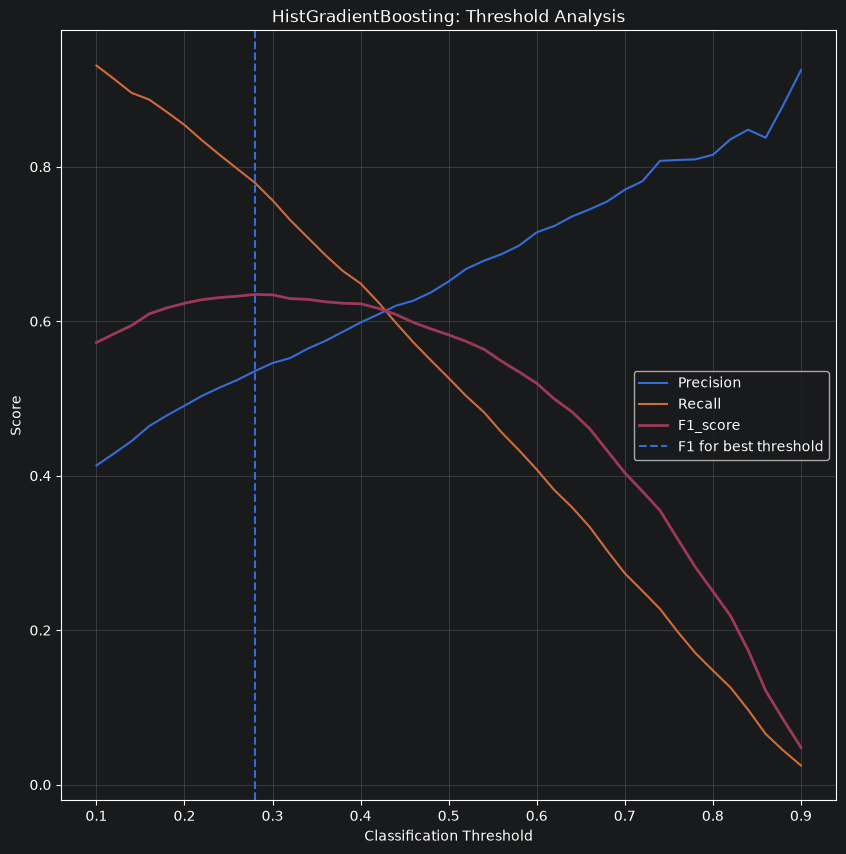

In [49]:
plt.figure(figsize = (10,10))
plt.plot(
    hgb_threshold_df["Threshold"],
    hgb_threshold_df["Precision"],
    label = "Precision"
)
plt.plot(
    hgb_threshold_df["Threshold"],
    hgb_threshold_df["Recall"],
    label = "Recall"
)
plt.plot(
    hgb_threshold_df["Threshold"],
    hgb_threshold_df["F1"],
    label = "F1_score",
    linewidth= 2
)
plt.axvline(
    best_hgb_row["Threshold"],
    linestyle = "--",
    label = "F1 for best threshold"
)
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("HistGradientBoosting: Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [50]:
import xgboost as xgb
print(xgb.__version__)

3.4.1


In [51]:
from xgboost import XGBClassifier
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators = 100,
        learning_rate = 0.1,
        max_depth = 4,
        subsample = 0.8,
        colsample_bytree = 0.8,
        objective = "binary:logistic",
        eval_metric = "logloss",
        random_state= 42,
        n_jobs = 1
    ))
])

In [52]:
y_train_xgb = y_train.map({
    "No" : 0,
    "Yes":1
})
scoring_xgb = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "f1_score": make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    "roc_auc": "roc_auc"
}
xgb_cv = cross_validate(
    xgb_model,
    X_train,
    y_train_xgb,
    cv = cv,
    scoring = scoring_xgb,
    n_jobs = 1,
    verbose = 2,
    error_score='raise'
)

for metric in scoring:
    values = xgb_cv[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f}"
          f"+/- {values.std():.4f}")

[CV] END .................................................... total time=   0.4s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
accuracy: 0.8012+/- 0.0047
precision: 0.6590+/- 0.0123
recall: 0.5231+/- 0.0192
f1_score: 0.5830+/- 0.0131
roc_auc: 0.8455+/- 0.0048


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.5s finished


In [53]:
xgb_oof_proba = cross_val_predict(
    xgb_model,
    X_train,
    y_train_xgb,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

xgb_oof_proba_yes = xgb_oof_proba[:, 1]

In [54]:
thresholds = np.arange(0.1, 0.91, 0.02)

xgb_threshold_results = []

for threshold in thresholds:

    predictions = np.where(
        xgb_oof_proba_yes >= threshold,
        1,
        0
    )

    xgb_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train_xgb, predictions, pos_label=1
        ),
        "Recall": recall_score(
            y_train_xgb, predictions, pos_label=1
        ),
        "F1": f1_score(
            y_train_xgb, predictions, pos_label=1
        )
    })

xgb_threshold_df = pd.DataFrame(xgb_threshold_results)

In [55]:
best_xgb_row = xgb_threshold_df.loc[
    xgb_threshold_df["F1"].idxmax()
]

print(best_xgb_row)

Threshold    0.280000
Precision    0.538961
Recall       0.777258
F1           0.636538
Name: 9, dtype: float64


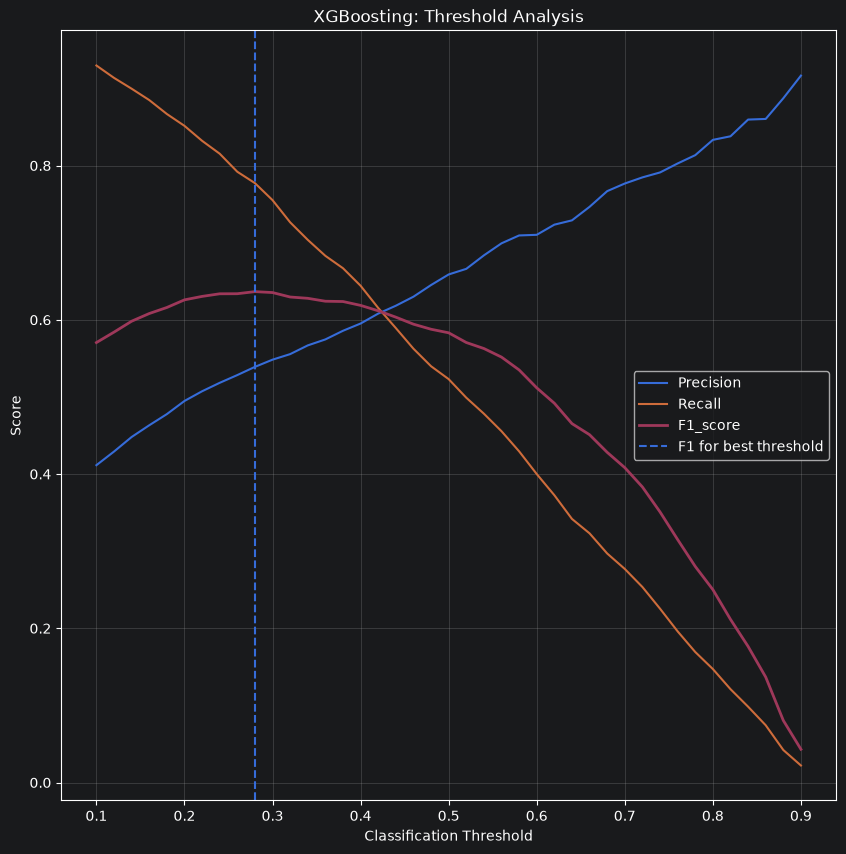

In [56]:
plt.figure(figsize = (10,10))
plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["Precision"],
    label = "Precision"
)
plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["Recall"],
    label = "Recall"
)
plt.plot(
    xgb_threshold_df["Threshold"],
    xgb_threshold_df["F1"],
    label = "F1_score",
    linewidth= 2
)
plt.axvline(
    best_xgb_row["Threshold"],
    linestyle = "--",
    label = "F1 for best threshold"
)
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("XGBoosting: Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [57]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="Yes", zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label="Yes", zero_division=0
    ),
    "f1_score": make_scorer(
        f1_score, pos_label="Yes", zero_division=0
    ),
    "roc_auc": "roc_auc"
}
rf_cv = cross_validate(
    rf_best_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    verbose=2
)

[CV] END .................................................... total time=   2.4s
[CV] END .................................................... total time=   2.4s
[CV] END .................................................... total time=   2.4s
[CV] END .................................................... total time=   2.4s
[CV] END .................................................... total time=   2.5s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   12.5s finished


In [58]:
hgb_cv = cross_validate(
    hgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    verbose=2
)

[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.5s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    2.9s finished


In [59]:
scoring_xgb = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "f1_score": make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    "roc_auc": "roc_auc"
}

xgb_cv = cross_validate(
    xgb_model,
    X_train,
    y_train_xgb,
    cv=cv,
    scoring=scoring_xgb,
    n_jobs=1,
    verbose=2
)

[CV] END .................................................... total time=   0.7s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.4s
[CV] END .................................................... total time=   0.4s
[CV] END .................................................... total time=   0.7s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    2.9s finished


In [60]:
logistic_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    verbose=2
)

[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.6s
[CV] END .................................................... total time=   0.1s
[CV] END .................................................... total time=   0.1s
[CV] END .................................................... total time=   0.2s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.9s finished


In [61]:
cv_results = {}
#Logistic Regression
cv_results["Logistic Regression"] = cross_validate(
    logistic_model, X_train, y_train,
    cv=cv, scoring=scoring, n_jobs=1, verbose=2
)

# Random Forest
cv_results["Random Forest"] = cross_validate(
    rf_best_model, X_train, y_train,
    cv=cv, scoring=scoring, n_jobs=1, verbose=2
)

# HistGradientBoosting
cv_results["HistGradientBoosting"] = cross_validate(
    hgb_model, X_train, y_train,
    cv=cv, scoring=scoring, n_jobs=1, verbose=2
)

# XGBoost
cv_results["XGBoost"] = cross_validate(
    xgb_model, X_train, y_train_xgb,
    cv=cv, scoring=scoring_xgb, n_jobs=1, verbose=2
)

[CV] END .................................................... total time=   0.1s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.1s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.2s finished


[CV] END .................................................... total time=   2.8s
[CV] END .................................................... total time=   2.8s
[CV] END .................................................... total time=   2.6s
[CV] END .................................................... total time=   2.8s
[CV] END .................................................... total time=   2.5s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   13.9s finished


[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.5s
[CV] END .................................................... total time=   0.5s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    2.9s finished


[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.3s finished


In [62]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_best_model,
    "HistGradientBoosting": hgb_model,
    "XGBoost": xgb_model
}

In [63]:
def cv_summarize(model_name, cv_results):
    summary={}
    for metric in ["accuracy", "precision", "recall", "f1_score", "roc_auc"]:
        values = cv_results[f"test_{metric}"]
        summary[metric] = values.mean()
        summary[f"{metric}_std"] = values.std()
    return pd.Series(summary, name = model_name)

In [64]:
cv_comparison = pd.DataFrame([cv_summarize(model_name,results)
                             for model_name, results in cv_results.items()])
cv_comparison = cv_comparison.sort_values(
    by = "f1_score",
    ascending = False
)

In [65]:
print(cv_comparison)

                      accuracy  accuracy_std  precision  precision_std  \
Random Forest         0.767644      0.003754   0.544066       0.005332   
Logistic Regression   0.802489      0.011554   0.654093       0.028925   
XGBoost               0.801244      0.004724   0.658994       0.012290   
HistGradientBoosting  0.799289      0.005103   0.651656       0.009685   

                        recall  recall_std  f1_score  f1_score_std   roc_auc  \
Random Forest         0.777258    0.015486  0.640004      0.006287  0.847405   
Logistic Regression   0.546488    0.022938  0.595262      0.022889  0.846059   
XGBoost               0.523077    0.019224  0.582993      0.013150  0.845540   
HistGradientBoosting  0.526421    0.033751  0.581752      0.020633  0.845337   

                      roc_auc_std  
Random Forest            0.005076  
Logistic Regression      0.005177  
XGBoost                  0.004836  
HistGradientBoosting     0.005151  


In [66]:
best_thresholds = {
    "Random Forest": 0.50,
    "HistGradientBoosting": 0.28,
    # Add your previously optimized thresholds:
    "Logistic Regression": 0.50,  # Replace if different
    "XGBoost": 0.28                # Replace if different
}

In [67]:
models = {
    "Random Forest": (rf_best_model, y_train),
    "Logistic Regression": (logistic_model, y_train),
    "HistGradientBoosting": (hgb_model, y_train),
    "XGBoost": (xgb_model, y_train_xgb)
}
oof_probabilities = {}
for name , (model, y_data) in models.items():

    probabilities = cross_val_predict(
        model,
        X_train,
        y_data,
        cv =cv,
        method = "predict_proba",
        n_jobs = 1
    )
    oof_probabilities[name] = probabilities[:,1]

In [68]:
from sklearn.metrics import roc_auc_score
threshold_overall_results = []
for name, (model, y_data) in models.items():
    threshold = best_thresholds[name]
    probabilities = oof_probabilities[name]
    predictions = (probabilities >= threshold).astype(int)
    y_true = (y_data.map({ "No": 0, "Yes": 1 }).to_numpy() if name!="XGBoost"
              else y_data.to_numpy())
    threshold_overall_results.append({
        "Model" : name,
        "Threshold" : threshold,
        "Accuracy" : accuracy_score(y_true, predictions),
        "Precision" : precision_score(y_true, predictions, zero_division = 0),
        "Recall" : recall_score(y_true, predictions, zero_division = 0),
        "F1_score" : f1_score(y_true, predictions, zero_division = 0),
        "ROC-AUC" : roc_auc_score(y_true, probabilities)
    })
result_comparison = pd.DataFrame(threshold_overall_results)
result_comparison = result_comparison.sort_values(by = "F1_score", ascending = False)
print(result_comparison.round(4))


                  Model  Threshold  Accuracy  Precision  Recall  F1_score  \
0         Random Forest       0.50    0.7676     0.5440  0.7773    0.6400   
3               XGBoost       0.28    0.7641     0.5390  0.7773    0.6365   
2  HistGradientBoosting       0.28    0.7616     0.5354  0.7793    0.6347   
1   Logistic Regression       0.50    0.8025     0.6536  0.5465    0.5953   

   ROC-AUC  
0   0.8470  
3   0.8453  
2   0.8450  
1   0.8457  


In [69]:
from catboost import CatBoostClassifier
cat_features = X_train.select_dtypes(
    include = ["object", "category", "str"]
).columns.tolist()
catboost_model = CatBoostClassifier(
    iterations = 1000,
    learning_rate = 0.03,
    depth = 6,
    loss_function = "Logloss",
    eval_metric = "AUC",
    random_state = 42,
    verbose = 100,
    auto_class_weights = "Balanced"
)
catboost_model.fit(
    X_train, y_train, cat_features = cat_features
)

0:	total: 183ms	remaining: 3m 3s
100:	total: 3.26s	remaining: 29s
200:	total: 6.24s	remaining: 24.8s
300:	total: 9.2s	remaining: 21.4s
400:	total: 12.7s	remaining: 18.9s
500:	total: 16.3s	remaining: 16.2s
600:	total: 19.9s	remaining: 13.2s
700:	total: 24s	remaining: 10.2s
800:	total: 27.9s	remaining: 6.93s
900:	total: 31.6s	remaining: 3.47s
999:	total: 35.5s	remaining: 0us


CatBoostClassifier(auto_class_weights='Balanced', depth=6, eval_metric='AUC', iterations=1000, learning_rate=0.03, loss_function='Logloss', random_state=42, verbose=100)

In [70]:
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix
)

y_pred_catboost = catboost_model.predict(X_test)
y_prob_catboost = catboost_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_catboost))

print("Precision:", precision_score(
    y_test, y_pred_catboost, pos_label="Yes"
))

print("Recall:", recall_score(
    y_test, y_pred_catboost, pos_label="Yes"
))

print("F1-score:", f1_score(
    y_test, y_pred_catboost, pos_label="Yes"
))

print("ROC-AUC:", roc_auc_score(
    y_test, y_prob_catboost
))

print("PR-AUC:", average_precision_score(
    y_test, y_prob_catboost, pos_label="Yes"
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_catboost))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, y_pred_catboost,
    labels=["No", "Yes"]
))

Accuracy: 0.7562189054726368
Precision: 0.5291902071563088
Recall: 0.7513368983957219
F1-score: 0.6209944751381216
ROC-AUC: 0.8293260893198255
PR-AUC: 0.6431949743206407

Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.76      0.82      1033
         Yes       0.53      0.75      0.62       374

    accuracy                           0.76      1407
   macro avg       0.71      0.75      0.72      1407
weighted avg       0.80      0.76      0.77      1407


Confusion Matrix:
[[783 250]
 [ 93 281]]


In [71]:
catboost_cv_model = CatBoostClassifier(
    iterations = 1000,
    learning_rate = 0.03,
    depth = 6,
    loss_function = "Logloss",
    eval_metric = "AUC",
    random_state = 42,
    verbose = False,
    auto_class_weights = "Balanced",
    thread_count = 1,
    cat_features = cat_features
)

In [72]:
fold_results =[]
for fold ,(train_idx, val_idx)in enumerate(cv.split(X_train, y_train), start = 1):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]
    catboost_cv_model.fit(
        X_fold_train,
        y_fold_train,
        cat_features = cat_features
    )
    y_pred = catboost_cv_model.predict(X_fold_val).ravel()
    y_prob = catboost_cv_model.predict_proba(X_fold_val)[:,1]
    results = {
        "fold": fold,
        "accuracy": accuracy_score(y_fold_val, y_pred),
        "precision": precision_score(
            y_fold_val, y_pred, pos_label="Yes", zero_division=0
        ),
        "recall": recall_score(
            y_fold_val, y_pred, pos_label="Yes", zero_division=0
        ),
        "f1": f1_score(
            y_fold_val, y_pred, pos_label="Yes", zero_division=0
        ),
        "roc_auc": roc_auc_score(
            y_fold_val, y_prob
        ),
        "pr_auc": average_precision_score(
            y_fold_val, y_prob, pos_label="Yes"
        )
    }

    fold_results.append(results)

    print(f"Fold {fold} completed.")


Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.


In [73]:
results_df = pd.DataFrame(fold_results)
print("Individual_fold_results\n")
print(results_df.round(4))
print(f"\nMean cv performance : {results_df.drop(columns = "fold").mean().round(4)}")
print(f"\nStandard deviation cv performance : {results_df.drop(columns = "fold").std().round(4)}")


Individual_fold_results

   fold  accuracy  precision  recall      f1  roc_auc  pr_auc
0     1    0.7609     0.5368  0.7324  0.6195   0.8391  0.6737
1     2    0.7529     0.5239  0.7692  0.6233   0.8417  0.6438
2     3    0.7751     0.5625  0.6923  0.6207   0.8397  0.6363
3     4    0.7742     0.5542  0.7692  0.6443   0.8455  0.6547
4     5    0.7707     0.5499  0.7559  0.6366   0.8543  0.6841

Mean cv performance : accuracy     0.7668
precision    0.5455
recall       0.7438
f1           0.6289
roc_auc      0.8441
pr_auc       0.6585
dtype: float64

Standard deviation cv performance : accuracy     0.0096
precision    0.0152
recall       0.0325
f1           0.0110
roc_auc      0.0062
pr_auc       0.0201
dtype: float64


In [74]:
# Calculate mean performance across the 5 folds
cv_mean = results_df.drop(columns="fold").mean()

# Calculate standard deviation across the 5 folds
cv_std = results_df.drop(columns="fold").std()

# Combine both into one table
cv_summary = pd.DataFrame({
    "Mean": cv_mean,
    "Std": cv_std
})

print(cv_summary.round(4))

             Mean     Std
accuracy   0.7668  0.0096
precision  0.5455  0.0152
recall     0.7438  0.0325
f1         0.6289  0.0110
roc_auc    0.8441  0.0062
pr_auc     0.6585  0.0201


In [79]:
from catboost import Pool, CatBoostClassifier

train_pool = Pool(
    X_train,
    y_train,
    cat_features=cat_features
)

param_grid = {
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05]
}

model = CatBoostClassifier(
    iterations=300,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    auto_class_weights="Balanced",
    verbose=False,
    thread_count=-1,
    allow_writing_files=False
)

grid_result = model.grid_search(
    param_grid,
    X=train_pool,
    cv=5,
    stratified=True,
    partition_random_seed=42,
    search_by_train_test_split=False,
    refit=True,
    verbose=False
)

Training on fold [0/5]

bestTest = 0.8544745601
bestIteration = 295

Training on fold [1/5]

bestTest = 0.8414407994
bestIteration = 280

Training on fold [2/5]

bestTest = 0.8380477297
bestIteration = 286

Training on fold [3/5]

bestTest = 0.8510227797
bestIteration = 299

Training on fold [4/5]

bestTest = 0.8647246269
bestIteration = 293

Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Training on fold [0/5]

bestTest = 0.8539684339
bestIteration = 299

Training on fold [1/5]

bestTest = 0.8432547556
bestIteration = 169

Training on fold [2/5]

bestTest = 0.8390842761
bestIteration = 206

Training on fold [3/5]

bestTest = 0.8515167588
bestIteration = 243

Training on fold [4/5]

bestTest = 0.8656316049
bestIteration = 211

Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Training on fold [0/5]

bestTest = 0.85447

In [82]:
print("Best parameters: ", grid_result["params"])

Best parameters:  {'depth': 4, 'learning_rate': 0.03}


In [89]:
cv_results = pd.DataFrame(grid_result["cv_results"])
print(cv_results.columns.tolist())
print(cv_results[["iterations", "test-AUC-mean", "test-AUC-std"]].
      sort_values(by = "test-AUC-mean", ascending = False).head(10).
      round(4))

['iterations', 'test-AUC-mean', 'test-AUC-std', 'test-Logloss-mean', 'test-Logloss-std', 'train-Logloss-mean', 'train-Logloss-std']
     iterations  test-AUC-mean  test-AUC-std
299         299         0.8498        0.0107
298         298         0.8498        0.0107
294         294         0.8498        0.0107
293         293         0.8498        0.0107
295         295         0.8498        0.0108
296         296         0.8498        0.0107
297         297         0.8498        0.0107
290         290         0.8498        0.0107
291         291         0.8498        0.0107
279         279         0.8498        0.0106
